# SMT figure
Run **Cell 1** once, then edit the settings in **Cell 2** and run it. Figures are saved as SVG in this notebook's folder.

In [26]:
# Cell 1: run this cell once. It only defines the functions; nothing is drawn yet.
"""
Single-molecule tracking figure from linked localizations.

Figure 1:  full field of view (contrast image, cell boxed) |
           zoom: single localization | localizations over time | linked trajectory
Figure 2:  all trajectories in the cell, coloured by Dapp

The cell is drawn as a capsule (rod with round ends) fitted to its Omnipose mask,
and in the zoomed panels it is turned so its long axis lies along the diagonal.

Notebook use:   main(["data.csv", "--fov", "...", "--mask", "..._seg.npy",
                      "--image", "..._wf_proj.tif", "--cell", "12", "--dt", "7"])

Data conventions (checked against the Omnipose masks)
  * a track = (fov_mask_id, cell_id_int, particle); particle ids restart per cell
  * x is the image ROW and y the image COLUMN, in pixels; pixel i spans [i, i+1)
"""
import argparse
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.patches import Rectangle
from matplotlib import cm, colors

OUTLINE = "black"
SPOT = "#2CA02C"           # green single localization
BOX = "#F2C14E"            # box marking the cell in the field of view
TRACK_CMAP = "viridis"     # time along a track
D_CMAP = "plasma"        # Dapp
D_MIN, D_MAX = 0.05, 1.0
SAVE_AS = ("svg",)
SHOW_BOX = False           # True draws a box around the chosen cell in the field-of-view panels
FLUO_CMAP = "gray"         # colour map of the fluorescence panel, e.g. "gray", "magma", "inferno"         # add "png", "pdf" here if you also want those
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9,
                     "svg.fonttype": "none", "pdf.fonttype": 42})


# ---------------------------------------------------------------- data
def load_masks(path):
    d = np.load(path, allow_pickle=True)
    if d.dtype == object:
        d = d.item()["masks"]
    return np.asarray(d)


def mask_contour(masks, cell):
    """Pixel contour of label == cell as (row, col), pixel centres at i + 0.5."""
    from skimage import measure
    cs = measure.find_contours(np.pad(masks == cell, 1).astype(float), 0.5)
    return max(cs, key=len) - 1 + 0.5


def step_max(t, px):
    p = t.sort_values("frame")[["x", "y"]].to_numpy()
    return (np.hypot(*np.diff(p, axis=0).T).max() * px) if len(p) > 1 else 0


def pick_track(d, px, max_step):
    """Longest track that moves (Rg > 0.15 µm) and has no implausible jumps."""
    best, best_n = None, -1
    for pid, t in d.groupby("particle"):
        xy = t[["x", "y"]].to_numpy()
        rg = np.sqrt(((xy - xy.mean(0)) ** 2).sum(axis=1).mean()) * px
        if rg > 0.15 and step_max(t, px) <= max_step and len(t) > best_n:
            best, best_n = pid, len(t)
    if best is None:
        best = d.groupby("particle").size().idxmax()
    return best


# ---------------------------------------------------------------- fluorescence movie
def find_movie(f):
    """Largest 3-D dataset in an open h5 file (the movie)."""
    import h5py
    found = []
    f.visititems(lambda name, obj: found.append(obj)
                 if isinstance(obj, h5py.Dataset) and obj.ndim == 3 else None)
    if not found:
        raise SystemExit("No 3-D image stack found in the h5 file.")
    return max(found, key=lambda d: d.size)


def fluo_projection(h5_path, frame_shape, kind="max", skip=0, chunk=500):
    """Combine all frames of the movie into one image (max, mean, std or sum).

    Reads the movie in chunks, so it never needs to fit in memory. The result is
    cached next to the notebook (<movie>_<kind>.npy), so the 20k frames are only
    read the first time."""
    import os, h5py
    cache = os.path.splitext(os.path.basename(h5_path))[0] + f"_{kind}_skip{skip}.npy"
    if os.path.exists(cache):
        img = np.load(cache)
    else:
        with h5py.File(h5_path, "r") as f:
            ds = find_movie(f)
            shp = ds.shape
            # which axis holds the frames? the one that is not part of the image size
            if shp[1:] in (frame_shape, frame_shape[::-1]):
                fax = 0
            elif shp[:2] in (frame_shape, frame_shape[::-1]):
                fax = 2
            else:
                fax = int(np.argmax(shp))
            n = shp[fax]
            print(f"Reading {ds.name}: shape {shp}, {n - skip} frames ({kind} projection)...")
            acc = acc2 = None
            for s0 in range(skip, n, chunk):
                sl = [slice(None)] * 3
                sl[fax] = slice(s0, min(s0 + chunk, n))
                blk = np.moveaxis(ds[tuple(sl)], fax, 0).astype(np.float64)
                if kind == "max":
                    part = blk.max(0)
                    acc = part if acc is None else np.maximum(acc, part)
                else:
                    acc = blk.sum(0) if acc is None else acc + blk.sum(0)
                    if kind == "std":
                        acc2 = (blk ** 2).sum(0) if acc2 is None else acc2 + (blk ** 2).sum(0)
            m = n - skip
            img = {"max": acc, "sum": acc, "mean": acc / m}.get(kind)
            if kind == "std":
                img = np.sqrt(np.maximum(acc2 / m - (acc / m) ** 2, 0))
        np.save(cache, img)
    if img.shape != tuple(frame_shape) and img.shape[::-1] == tuple(frame_shape):
        img = img.T                               # match the mask orientation
    if img.shape != tuple(frame_shape):
        print(f"Warning: fluorescence image is {img.shape}, mask is {frame_shape}; "
              "the panels may not line up.")
    return img


# ---------------------------------------------------------------- geometry
def to_display(rowcol, px):
    """(row, col) pixels -> display µm: X = col, Y = -row (same view as Fiji, no mirroring)."""
    rowcol = np.asarray(rowcol, float)
    return np.c_[rowcol[:, 1], -rowcol[:, 0]] * px


def fit_capsule(contour_disp):
    """Capsule fitted to a cell contour: centre, long-axis unit vector, length, width."""
    m = contour_disp.mean(0)
    _, _, vt = np.linalg.svd(contour_disp - m, full_matrices=False)
    u, v = vt[0], vt[1]
    pu, pv = (contour_disp - m) @ u, (contour_disp - m) @ v
    centre = m + u * (pu.max() + pu.min()) / 2 + v * (pv.max() + pv.min()) / 2
    L, W = pu.max() - pu.min(), pv.max() - pv.min()
    return centre, u, L, min(W, L)


def capsule_path(L, W, n=200):
    """Capsule outline centred at 0 with its long axis along +x."""
    r, h = W / 2, max(L / 2 - W / 2, 0)
    a = np.linspace(-np.pi / 2, np.pi / 2, n)
    right = np.c_[h + r * np.cos(a), r * np.sin(a)]
    left = np.c_[-h - r * np.cos(a), -r * np.sin(a)]
    return np.vstack([right, left])


def cell_frame(centre, u, angle_deg):
    """Function mapping display µm -> zoom-panel µm, cell centred, long axis at angle_deg."""
    theta = np.deg2rad(angle_deg) - np.arctan2(u[1], u[0])
    R = np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]])
    return lambda p: (np.asarray(p) - centre) @ R.T


# ---------------------------------------------------------------- drawing
def setup_zoom(ax, half):
    ax.set_xlim(-half, half)
    ax.set_ylim(-half, half)
    ax.set_aspect("equal")
    ax.axis("off")


def draw_outline(ax, outline, color=OUTLINE, lw=2.0):
    ax.plot(*np.vstack([outline, outline[:1]]).T, color=color, lw=lw,
            solid_joinstyle="round", zorder=4)


SCALEBAR_LABELS = False    # True puts the length (e.g. "5 µm") next to each scale bar


def scalebar(ax, x0, y0, length, color="#222", fontsize=8, label_above=False):
    ax.plot([x0, x0 + length], [y0, y0], color=color, lw=2.5, solid_capstyle="butt", zorder=5)
    if not SCALEBAR_LABELS:
        return
    off = 0.03 * np.ptp(ax.get_ylim()) if not label_above else -0.008 * np.ptp(ax.get_ylim())
    txt = ax.text(x0 + length / 2, y0 - off, f"{length:g} µm", ha="center",
                  va="bottom" if label_above else "top", fontsize=fontsize, color=color, zorder=5)
    if label_above:   # label on top of an image: dark halo so it stays readable
        import matplotlib.patheffects as pe
        txt.set_path_effects([pe.withStroke(linewidth=2, foreground="black")])


def time_colorbar(fig, ax_ref, norm, cmap, label):
    pos = ax_ref.get_position()
    cax = fig.add_axes([pos.x1 + 0.01, pos.y0 + pos.height * 0.2, 0.008, pos.height * 0.6])
    cb = fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax)
    cb.set_label(label, fontsize=8)
    cb.ax.tick_params(labelsize=7)
    cb.outline.set_visible(False)


# ---------------------------------------------------------------- main
def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("csv")
    ap.add_argument("--fov", required=True, help="value of fov_mask_id in the CSV")
    ap.add_argument("--mask", required=True, help="Omnipose *_seg.npy for this field of view")
    ap.add_argument("--cell", type=int)
    ap.add_argument("--image", help="contrast image (.tif); adds the field-of-view panel")
    ap.add_argument("--fluo", help="SMT movie (.h5); adds a combined-fluorescence panel")
    ap.add_argument("--fluo-kind", default="max", choices=["max", "mean", "std", "sum"],
                    help="how the frames are combined (default: max projection)")
    ap.add_argument("--fluo-skip", type=int, default=0, help="ignore the first N frames")
    ap.add_argument("--track", type=int, help="particle id (default: chosen automatically)")
    ap.add_argument("--px", type=float, default=0.106, help="pixel size in µm")
    ap.add_argument("--dt", type=float, help="frame interval in ms (colour bar in ms)")
    ap.add_argument("--angle", type=float, default=135,
                    help="angle of the cell's long axis in the zoomed panels (degrees)")
    ap.add_argument("--max-step", type=float, default=0.8,
                    help="µm; tracks with a larger single step are not auto-picked")
    ap.add_argument("--scalebar", type=float, default=0.5, help="zoom scale bar (µm)")
    ap.add_argument("--fov-scalebar", type=float, default=5, help="field-of-view scale bar (µm)")
    ap.add_argument("--smooth", type=int, help="(no longer used; the cell is a capsule)")
    ap.add_argument("--all", action="store_true",
                    help="plot every (clean) track of the cell instead of one track")
    ap.add_argument("--list", action="store_true", help="list candidate cells and exit")
    ap.add_argument("--out", default="smt_figure")
    a = ap.parse_args(argv)

    df = pd.read_csv(a.csv)
    df = df[df.fov_mask_id == a.fov]
    masks = load_masks(a.mask)

    if a.list:
        rows = []
        for cell, d in df.groupby("cell_id_int"):
            pid = pick_track(d, a.px, a.max_step)
            rows.append((cell, d.particle.nunique(), pid, (d.particle == pid).sum()))
        out = pd.DataFrame(rows, columns=["cell", "n_tracks", "best_track", "best_track_locs"])
        print(out.sort_values("best_track_locs", ascending=False).head(25).to_string(index=False))
        return

    d = df[df.cell_id_int == a.cell]
    if d.empty:
        raise SystemExit(f"No localizations for {a.fov} cell {a.cell}")
    pid = a.track if a.track is not None else pick_track(d, a.px, a.max_step)
    t = d[d.particle == pid].sort_values("frame")

    # geometry: everything in display µm, then into the zoom frame
    contour = to_display(mask_contour(masks, a.cell), a.px)
    centre, u, L, W = fit_capsule(contour)
    zoom = cell_frame(centre, u, a.angle)
    cap = capsule_path(L, W)
    th = np.deg2rad(a.angle)
    cap = cap @ np.array([[np.cos(th), np.sin(th)], [-np.sin(th), np.cos(th)]])
    half = max(np.abs(cap).max(axis=0)) + 0.15          # square zoom window
    tr = zoom(to_display(t[["x", "y"]].to_numpy(), a.px))

    # tracks shown in the panels: the chosen one, or all tracks without implausible jumps
    steps = d.groupby("particle").apply(lambda g: step_max(g, a.px))
    clean = steps[steps <= a.max_step].index
    n_removed = len(steps) - len(clean)
    d_clean = d[d.particle.isin(clean)]
    show_ids = list(clean) if a.all else [pid]
    tracks = []                              # (positions in zoom frame, time within track)
    for tid in show_ids:
        g = d[d.particle == tid].sort_values("frame")
        tracks.append((zoom(to_display(g[["x", "y"]].to_numpy(), a.px)),
                       (g.frame.to_numpy() - g.frame.min()) * (a.dt if a.dt else 1)))

    fr = t.frame.to_numpy() - t.frame.min()
    tscale = a.dt if a.dt else 1
    tt = fr * tscale
    norm = colors.Normalize(0, max(x[1].max() for x in tracks))
    cmap = plt.get_cmap(TRACK_CMAP)
    tlabel = "time (ms)" if a.dt else "time (frames)"

    # ---------------- Figure 1 ----------------
    fov_imgs = []                                     # (title, image, colormap)
    if a.image:
        import tifffile
        fov_imgs.append(("Field of view", tifffile.imread(a.image).astype(float), "gray"))
    if a.fluo:
        fl = fluo_projection(a.fluo, masks.shape, a.fluo_kind, a.fluo_skip)
        fov_imgs.append(("Fluorescence", fl, FLUO_CMAP))
    if fov_imgs:
        nrow, ncol = fov_imgs[0][1].shape
        fov_w = 2.6 * ncol / nrow
        nf = len(fov_imgs)
        fig = plt.figure(figsize=(nf * fov_w + 3 * 2.6 + 0.9, 2.9))
        gs = fig.add_gridspec(1, nf + 3, width_ratios=[fov_w] * nf + [2.6] * 3, wspace=0.08,
                              left=0.01, right=0.93, top=0.88, bottom=0.04)
        axfs = [fig.add_subplot(gs[i]) for i in range(nf)]
        p = [fig.add_subplot(gs[nf + i]) for i in range(3)]
        for axf, (ttl, im, cmp) in zip(axfs, fov_imgs):
            vmin, vmax = np.percentile(im, [0.5, 99.8])
            axf.imshow(im, cmap=cmp, vmin=vmin, vmax=vmax, interpolation="nearest",
                       extent=[0, ncol * a.px, -nrow * a.px, 0])
            axf.set_aspect("equal")
            axf.axis("off")
            axf.set_title(ttl, fontsize=10, pad=4)
            if SHOW_BOX:   # box around the cell (same physical size as the zoom window)
                axf.add_patch(Rectangle(centre - half, 2 * half, 2 * half, fill=False,
                                        ec=BOX, lw=1.2, zorder=5))
        scalebar(axfs[0], 2.0, -nrow * a.px + 1.4, a.fov_scalebar, color="white",
                 fontsize=9, label_above=True)
    else:
        fig, p = plt.subplots(1, 3, figsize=(3 * 2.6 + 0.9, 2.9))
        fig.subplots_adjust(left=0.01, right=0.9, wspace=0.08, top=0.88, bottom=0.04)

    if a.all:
        titles = ["Single localizations", "Localizations over time", "Linked trajectories"]
    else:
        titles = ["Single localization", "Localizations over time", "Linked trajectory"]
    for ax, ttl in zip(p, titles):
        draw_outline(ax, cap)
        setup_zoom(ax, half)
        ax.set_title(ttl, fontsize=10, pad=4)
    scalebar(p[0], -half + 0.05, -half + 0.12, a.scalebar)

    # spot size: smaller when many molecules are shown
    halo = [(240, 0.12), (120, 0.25), (40, 1.0)] if not a.all else [(110, 0.12), (55, 0.25), (18, 1.0)]
    dot, line, ldot = (7, 0.9, 3) if not a.all else (4, 0.6, 1.5)
    for trk, tt_ in tracks:
        x0, y0 = trk[len(trk) // 2]      # one real localization (middle of each track)
        for sz, al in halo:
            p[0].scatter(x0, y0, s=sz, color=SPOT, alpha=al, lw=0, zorder=3)
        p[1].scatter(trk[:, 0], trk[:, 1], c=tt_, cmap=cmap, norm=norm, s=dot,
                     edgecolor="white", lw=0.2, zorder=3)
        seg = np.stack([trk[:-1], trk[1:]], 1)
        lc = LineCollection(seg, cmap=cmap, norm=norm, lw=line, capstyle="round", zorder=2)
        lc.set_array(tt_[:-1])
        p[2].add_collection(lc)
        p[2].scatter(trk[:, 0], trk[:, 1], c=tt_, cmap=cmap, norm=norm, s=ldot, lw=0, zorder=3)
    if a.all:
        tlabel = "time within track (ms)" if a.dt else "time within track (frames)"
    time_colorbar(fig, p[2], norm, cmap, tlabel)

    for ext in SAVE_AS:
        fig.savefig(f"{a.out}.{ext}", dpi=600, bbox_inches="tight")
    plt.close(fig)

    # ---------------- Figure 2: all trajectories ----------------
    fig, ax = plt.subplots(figsize=(2.9, 2.9))
    fig.subplots_adjust(left=0.02, right=0.82, top=0.88, bottom=0.04)
    draw_outline(ax, cap)
    setup_zoom(ax, half)
    dn = colors.LogNorm(D_MIN, D_MAX, clip=True)     # same scale for every cell in the FOV
    dcm = plt.get_cmap(D_CMAP)
    for _, g in d_clean.sort_values("frame").groupby("particle"):
        q = zoom(to_display(g[["x", "y"]].to_numpy(), a.px))
        ax.plot(q[:, 0], q[:, 1], color=dcm(dn(g.Dapp.iloc[0])), lw=0.8, alpha=0.9)
    scalebar(ax, -half + 0.05, -half + 0.12, a.scalebar)
    ax.set_title(f"All trajectories (n = {len(clean)})", fontsize=10, pad=4)
    time_colorbar(fig, ax, dn, dcm, "D$_{app}$ (µm²/s)")
    for ext in SAVE_AS:
        fig.savefig(f"{a.out}_all_tracks.{ext}", dpi=600, bbox_inches="tight")
    plt.close(fig)

    print(f"{a.fov} cell {a.cell}: {len(steps)} tracks, {n_removed} removed (a step > {a.max_step} µm), "
          f"{len(clean)} shown in the all-tracks plots; capsule {L:.2f} x {W:.2f} µm")
    if not a.all:
        print(f"  single-track panels: track {pid}, {len(t)} localizations, "
              f"max step {step_max(t, a.px):.2f} µm, Dapp={t.Dapp.iloc[0]:.3f} µm²/s")


C:\Users\tomase1\AppData\Local\Temp\ipykernel_29300\3944872698.py:262: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  steps = d.groupby("particle").apply(lambda g: step_max(g, a.px))


20261020_Nery_b7b8dc02.npy cell 31: 15 tracks, 7 removed (a step > 0.8 µm), 8 shown in the all-tracks plots; capsule 2.50 x 0.89 µm
C:\Users\tomase1\Eve's_plots\40gemecoli_cell_all.svg


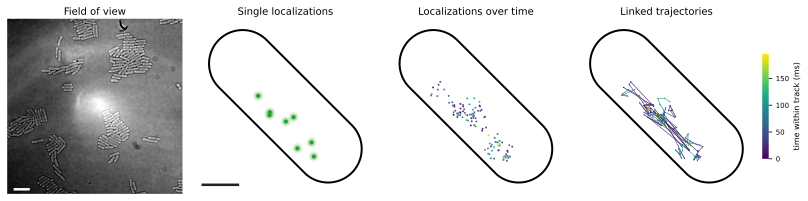

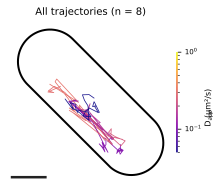

In [58]:
# Cell 2: edit the settings below, then run this cell to make the figures.
import os
from IPython.display import SVG, display

# --- folders on your computer (keep the r before the quotes) ---
data_dir = r"\\home.org.aalto.fi\tomase1\data\Documents\Aalto\microscopy data\40gem_ecoli_15deg_21.10.26"
mask_dir = r"\\home.org.aalto.fi\tomase1\data\Documents\Aalto\microscopy data\40gem_ecoli_15deg_21.10.26"

# --- file names inside those folders (check with Cell 3 if unsure) ---
csv_file   = "tracks_exp_4c06a400_a_d61def66.csv"
mask_file  = "261020_EN_Ec_64_M9glyCAAT_None_D_wf_proj_seg.npy"
image_file = "261020_EN_Ec_64_M9glyCAAT_None_D_wf_proj.tif"   # contrast image; None = leave out

# --- what to plot ---
fov        = "20261020_Nery_b7b8dc02.npy"  # value of fov_mask_id in the CSV (not a path)
cell       = 31
all_tracks = True      # True = every track in the cell (jumpy tracks removed); False = one track
dt         = 7         # frame interval in ms
angle      = 135       # tilt of the cell in the zoomed panels: 135 = to the left, 45 = to the right, 0 = horizontal
out        = "40gemecoli_cell_all" if all_tracks else "40gemecolig_cell"   # file name; saved as SVG here

args = [
    os.path.join(data_dir, csv_file),
    "--fov",   fov,
    "--mask",  os.path.join(mask_dir, mask_file),
    "--cell",  str(cell),
    "--dt",    str(dt),
    "--angle", str(angle),
    "--out",   out,
]
if image_file:
    args += ["--image", os.path.join(mask_dir, image_file)]
if all_tracks:
    args += ["--all"]

main(args)

print(os.path.abspath(out + ".svg"))
display(SVG(out + ".svg"))
display(SVG(out + "_all_tracks.svg"))


In [ ]:
# Cell 3 (optional): list the files in each folder, to copy the exact names into Cell 2.
import os
print(os.listdir(data_dir))
print(os.listdir(mask_dir))
